# Hazard Detection for Human Intervention in Autonomous Robot Navigation

This project asks whether a human operator should allow an autonomous robot to
continue navigating or intervene when the robot's visual input suggests a hazard.

The main evaluation metric is precision while maintaining at least 95% hazard recall.

In [1]:
##import all the packages needed for 
import os 
import glob 
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler 
from sklearn.pipeline import Pipeline 
from sklearn.ensemble import HistGradientBoostingClassifier 
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans 
from sklearn.metrics import (
    precision_score,
    recall_score,
    precision_recall_curve,
    confusion_matrix, 
    silhouette_score
)
SEED = 42
#anything with randomness can be reproduced. 
np.random.seed(SEED)

In [2]:
## setting up all paths 
ROOT = "/home/jovyan/CSCI_5622"

EMBEDDING_DIR = os.path.join(ROOT, "embeddings")
METADATA_DIR = os.path.join(ROOT, "metadata")

train_embedding_path = os.path.join(EMBEDDING_DIR, "training_mixed_embs.npy")
test_embedding_path = os.path.join(EMBEDDING_DIR, "test_embs.npy")
train_label_path = os.path.join(METADATA_DIR, "training_mixed_frames_labels.csv")
test_label_path = os.path.join(METADATA_DIR, "test_frames_labels.csv")
train_env_path = os.path.join(METADATA_DIR, "training_mixed_set_frames_envs.csv")

In [3]:
## just check that all paths exist 
paths_to_check = [
    train_embedding_path,
    test_embedding_path,
    train_label_path,
    test_label_path,
    train_env_path
]

for path in paths_to_check:
    print(os.path.exists(path), path)

True /home/jovyan/CSCI_5622/embeddings/training_mixed_embs.npy
True /home/jovyan/CSCI_5622/embeddings/test_embs.npy
True /home/jovyan/CSCI_5622/metadata/training_mixed_frames_labels.csv
True /home/jovyan/CSCI_5622/metadata/test_frames_labels.csv
True /home/jovyan/CSCI_5622/metadata/training_mixed_set_frames_envs.csv


In [4]:
#Load Embeddings 
## each row is one robot camera frame. 
## each frame is 512 CLIP features - visual representations 
## 144603 training frames and 512 features 
X_train = np.load(train_embedding_path)
X_test = np.load(test_embedding_path)

print("Training embeddings:", X_train.shape)
print("Test embeddings:", X_test.shape)

Training embeddings: (144603, 512)
Test embeddings: (129846, 512)


In [5]:
## Load Labels 
## embeddings are the X and csv gives us the y
train_labels_df = pd.read_csv(train_label_path)
test_labels_df = pd.read_csv(test_label_path)

print(train_labels_df.head())
print(test_labels_df.head())

   frame_id  label
0         0      1
1         1      1
2         2      1
3         3      1
4         4      1
   frame_id  label
0         0      7
1         1      7
2         2      7
3         3      7
4         4      7


In [6]:
print("Training embeddings:", len(X_train))
print("Training labels:", len(train_labels_df))

print("\nTest embeddings:", len(X_test))
print("Test labels:", len(test_labels_df))

assert len(X_train) == len(train_labels_df)
assert len(X_test) == len(test_labels_df)

Training embeddings: 144603
Training labels: 144603

Test embeddings: 129846
Test labels: 129846


In [7]:
print("Training original labels:")
print(train_labels_df["label"].value_counts().sort_index())
print("\nTest original labels:")
print(test_labels_df["label"].value_counts().sort_index())

Training original labels:
label
0     50241
1      5868
2      5460
3      5621
4      4474
5     13295
6       707
7      4751
8     14318
9       597
10     6014
11     4811
12      659
13      174
14      253
15       39
16      372
17      169
18      211
19    12551
20    14018
Name: count, dtype: int64

Test original labels:
label
0     45270
1      4976
2      5201
3      4619
4      4588
5     12056
6       561
7      4305
8     13358
9       236
10     5604
11     4236
12      538
13       51
14      136
15      109
16      395
17      157
18       93
19    11716
20    11641
Name: count, dtype: int64


In [8]:
# convert the original multiclass labels into either 0 = normal and 1 = hazard 
y_train_original = train_labels_df["label"].to_numpy()
y_test_original = test_labels_df["label"].to_numpy()

y_train = np.where(y_train_original == 0, 0, 1)
y_test = np.where(y_test_original == 0, 0, 1)

In [9]:
# Check the binary class balance to see how much of the data are hazards 
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

print("Training:")
print(train_counts)

print("\nTest:")
print(test_counts)

print("\nTraining hazard rate:", round(y_train.mean(), 4))

print("Test hazard rate:",round(y_test.mean(), 4))

Training:
0    50241
1    94362
Name: count, dtype: int64

Test:
0    45270
1    84576
Name: count, dtype: int64

Training hazard rate: 0.6526
Test hazard rate: 0.6514


In [10]:
# Load the metadata and create environments 
train_env_df = pd.read_csv(train_env_path)
print(train_env_df.head())
print(train_env_df.columns)
print(train_env_df.shape)
env_col = train_env_df.columns[-1]
env_values = train_env_df[env_col].to_numpy()
print(pd.Series(env_values).value_counts().sort_index())

   frame_id  env
0         0    1
1         1    1
2         2    1
3         3    1
4         4    1
Index(['frame_id', 'env'], dtype='object')
(144603, 2)
0    48383
1    54084
2    42136
Name: count, dtype: int64


In [11]:
# hold out one entire environment for validation. 
# hold out around 20% 
env_counts = pd.Series(env_values).value_counts()
target_size = 0.20 * len(env_values)
val_env = (env_counts - target_size).abs().idxmin()
print("Validation environment:", val_env)

Validation environment: 2


In [12]:
# Now we can split so that we have: 
# Development training, fit models, environment validation, 
# choose hyperparameters + thresholds, offical test set and then a final evalutation 
val_mask = env_values == val_env
train_mask = env_values != val_env

X_dev_train = X_train[train_mask]
y_dev_train = y_train[train_mask]
y_dev_original = y_train_original[train_mask]

X_val = X_train[val_mask]
y_val = y_train[val_mask]
y_val_original = y_train_original[val_mask]

print("Development training:", X_dev_train.shape)
print("Validation:", X_val.shape)

print("\nValidation class counts:")
print(pd.Series(y_val).value_counts())

Development training: (102467, 512)
Validation: (42136, 512)

Validation class counts:
1    27811
0    14325
Name: count, dtype: int64


In [13]:
## Defining the locked metric 
# Setting Recall >= 95%
# In this situation false negatives are dangerous - when there is a hazard but the robot keeps moving
def precision_at_95_recall(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)
    # precision_recall_curve returns one extra precision/recall point
    # that has no matching threshold.
    precision = precision[:-1]
    recall = recall[:-1]
    valid = recall >= 0.95
    if not np.any(valid):
        return None

    valid_precision = precision[valid]
    valid_recall = recall[valid]
    valid_thresholds = thresholds[valid]

    best_index = np.argmax(valid_precision)

    return {"precision": valid_precision[best_index], "recall": valid_recall[best_index], "threshold": valid_thresholds[best_index]}

In [14]:
## Baseline 1 - Always A Hazard
# This baseline is that we will stop the robot every single time 
# because we assume there is always a hazard
# recall is 100%
baseline1_pred = np.ones(len(y_val), dtype=int)
baseline1_precision = precision_score(y_val, baseline1_pred)
baseline1_recall = recall_score(y_val,baseline1_pred)
print("Always Hazard Baseline")
print("Precision:", baseline1_precision)
print("Recall:", baseline1_recall)

Always Hazard Baseline
Precision: 0.6600294285171825
Recall: 1.0


In [15]:
## Baseline 2 - distance from normal CLIP mean 
# take every normal training frame and calculate its average 512 dimensional representation.
# larger distance - image looks less like a normal training frame. 
normal_mean = X_dev_train[y_dev_train == 0].mean(axis=0)
val_distance = np.linalg.norm(X_val - normal_mean, axis=1)
baseline2_result = precision_at_95_recall(y_val, val_distance)
print("CLIP Distance Baseline")
print(baseline2_result)

CLIP Distance Baseline
{'precision': np.float64(0.7615027802587225), 'recall': np.float64(0.950379346301823), 'threshold': np.float16(4.13)}


In [16]:
## Tune Logistic Regression 
# For each C value the threshold is chosen to maintain 95% recall. 
C_values = [0.01, 0.1, 1, 10] # C controls the regularization. goes from strong to weak 
logistic_tuning_results = []
for C in C_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            C=C,
            max_iter=1000,
            random_state=SEED
        ))
    ])

    model.fit(X_dev_train, y_dev_train)
    scores = model.predict_proba( X_val)[:, 1]
    result = precision_at_95_recall(y_val,scores)

    logistic_tuning_results.append({
        "C": C,
        "Precision": result["precision"],
        "Recall": result["recall"],
        "Threshold": result["threshold"]
    })

logistic_tuning_df = pd.DataFrame(
    logistic_tuning_results
)

logistic_tuning_df

,C,Precision,Recall,Threshold
0,0.01,0.809318,0.95002,0.794009
1,0.10,0.775287,0.95002,0.887274
2,1.00,0.767339,0.95002,0.929432
3,10.00,0.761149,0.95002,0.865120


In [17]:
# Logistic Regression Settings 
# here the configurations have been constrained to >=95%. 
# high precision = fewer unnecessary interventions 
best_logistic_row = logistic_tuning_df.loc[logistic_tuning_df["Precision"].idxmax()]
best_logistic_C = float(best_logistic_row["C"])
print("Best C:", best_logistic_C)
print(best_logistic_row)

Best C: 0.01
C            0.010000
Precision    0.809318
Recall       0.950020
Threshold    0.794009
Name: 0, dtype: float64


In [18]:
## Fit the Logistic Model 
## Put through the pipeline and fit based on the training and fine precision and recall. 
best_logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        C=best_logistic_C,
        max_iter=1000,
        random_state=SEED
    ))
])

best_logistic_model.fit(X_dev_train, y_dev_train)
logistic_val_scores = (best_logistic_model.predict_proba(X_val)[:, 1])
best_logistic_result = precision_at_95_recall(y_val, logistic_val_scores)
print(best_logistic_result)

{'precision': np.float64(0.8093181400477854), 'recall': np.float64(0.9500197763474884), 'threshold': np.float64(0.7940088986145019)}


In [19]:
## Gradient Boosting 
# Can learn nonlinear effects, interactions between features, more complicated boundaries
# Learning rate and iteration count trade off with eachother
# Smaller learning rates generally need more boosting iterations 
# Small sanity check here 
boost_tuning_results = []
depth_values = [3, 6]
learning_rates = [0.05, 0.1]
iteration_values = [100, 200]
for depth in depth_values:
    for lr in learning_rates:
        for iterations in iteration_values:
            model = HistGradientBoostingClassifier(
                max_depth=depth,
                learning_rate=lr,
                max_iter=iterations,
                random_state=SEED
            )
            model.fit(X_dev_train, y_dev_train)
            scores = model.predict_proba(X_val)[:, 1]
            result = precision_at_95_recall(y_val, scores)
            boost_tuning_results.append({
                "Max Depth": depth,
                "Learning Rate": lr,
                "Iterations": iterations,
                "Precision": result["precision"],
                "Recall": result["recall"],
                "Threshold": result["threshold"]
            })

boost_tuning_df = pd.DataFrame(boost_tuning_results)

boost_tuning_df.sort_values("Precision", ascending=False)

,Max Depth,Learning Rate,Iterations,Precision,Recall,Threshold
2,3,0.10,100,0.797230,0.950020,0.459587
1,3,0.05,200,0.795669,0.950020,0.465792
0,3,0.05,100,0.790125,0.950020,0.492422
3,3,0.10,200,0.774628,0.950020,0.360558
7,6,0.10,200,0.771732,0.950020,0.326605
6,6,0.10,100,0.771303,0.950020,0.358331
4,6,0.05,100,0.768879,0.950020,0.459177
5,6,0.05,200,0.767657,0.950056,0.405379


In [20]:
## Boosting Settings 
best_boost_row = boost_tuning_df.loc[boost_tuning_df["Precision"].idxmax()]
print(best_boost_row)

Max Depth          3.000000
Learning Rate      0.100000
Iterations       100.000000
Precision          0.797230
Recall             0.950020
Threshold          0.459587
Name: 2, dtype: float64


In [21]:
best_boost_model = HistGradientBoostingClassifier(
    max_depth=int(
        best_boost_row["Max Depth"]
    ),
    learning_rate=float(
        best_boost_row["Learning Rate"]
    ),
    max_iter=int(
        best_boost_row["Iterations"]
    ),
    random_state=SEED
)

best_boost_model.fit(X_dev_train, y_dev_train)
boost_val_scores = (best_boost_model.predict_proba(X_val)[:, 1])
best_boost_result = precision_at_95_recall(y_val, boost_val_scores)
print(best_boost_result)

{'precision': np.float64(0.7972300171992396), 'recall': np.float64(0.9500197763474884), 'threshold': np.float64(0.45958656732288855)}


In [22]:
## Comparing Validaton Results 
validation_results = pd.DataFrame({
    "Method": [
        "Always Hazard",
        "CLIP Distance",
        "Logistic Regression",
        "Gradient Boosting"
    ],
    "Precision": [
        baseline1_precision,
        baseline2_result["precision"],
        best_logistic_result["precision"],
        best_boost_result["precision"]
    ],
    "Recall": [
        baseline1_recall,
        baseline2_result["recall"],
        best_logistic_result["recall"],
        best_boost_result["recall"]
    ]
})
validation_results

,Method,Precision,Recall
0,Always Hazard,0.660029,1.000000
1,CLIP Distance,0.761503,0.950379
2,Logistic Regression,0.809318,0.950020
3,Gradient Boosting,0.797230,0.950020


In [23]:
# Set the tresholds
logistic_threshold = (best_logistic_result["threshold"])
boost_threshold = (best_boost_result["threshold"])
distance_threshold = (baseline2_result["threshold"])
print("Logistic threshold:", logistic_threshold)
print("Boost threshold:", boost_threshold)
print("Distance threshold:", distance_threshold)

Logistic threshold: 0.7940088986145019
Boost threshold: 0.45958656732288855
Distance threshold: 4.13


In [24]:
if (
    best_boost_result["precision"]
    > best_logistic_result["precision"]
):
    validation_best_name = "Gradient Boosting"
    validation_best_model = best_boost_model
    validation_best_scores = boost_val_scores
    validation_best_threshold = boost_threshold

else:
    validation_best_name = "Logistic Regression"
    validation_best_model = best_logistic_model
    validation_best_scores = logistic_val_scores
    validation_best_threshold = logistic_threshold

print(
    "Best validation model:",
    validation_best_name
)

Best validation model: Logistic Regression


In [25]:
validation_best_pred = (
    validation_best_scores
    >= validation_best_threshold
).astype(int)

## Robustness Check: Leave-One-Environment-Out Cross-Validation

The main analysis holds out one complete environment for validation to avoid leakage
between similar video frames. I also check whether the selected Logistic Regression model 
is stable when each of the three training environments is
held out in turn. This is a robustness check. 

In [26]:
from sklearn.model_selection import LeaveOneGroupOut
logo = LeaveOneGroupOut()
print("Number of environment folds:", logo.get_n_splits(X_train, y_train, groups=env_values))

Number of environment folds: 3


In [27]:
# Evaluate the already-selected Logistic Regression setting
# while holding out each environment once.

logistic_fold_results = []

for train_idx, val_idx in logo.split(
    X_train,
    y_train,
    groups=env_values
):

    held_out_env = np.unique(
        env_values[val_idx]
    )[0]

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            C=best_logistic_C,
            max_iter=1000,
            random_state=SEED
        ))
    ])

    model.fit(
        X_train[train_idx],
        y_train[train_idx]
    )

    scores = model.predict_proba(
        X_train[val_idx]
    )[:, 1]

    result = precision_at_95_recall(
        y_train[val_idx],
        scores
    )

    logistic_fold_results.append({
        "Held-out Environment": held_out_env,
        "Precision at >=95% Recall": result["precision"],
        "Recall": result["recall"],
        "Threshold": result["threshold"],
        "Sample Size": len(val_idx)
    })

logistic_fold_df = pd.DataFrame(
    logistic_fold_results
)

logistic_fold_df

,Held-out Environment,Precision at >=95% Recall,Recall,Threshold,Sample Size
0,0,0.841825,0.950039,0.427596,48383
1,1,0.873944,0.950038,0.428908,54084
2,2,0.809318,0.950020,0.794009,42136


In [28]:
print(
    "Mean precision:",
    logistic_fold_df[
        "Precision at >=95% Recall"
    ].mean()
)

print(
    "Std precision:",
    logistic_fold_df[
        "Precision at >=95% Recall"
    ].std()
)

Mean precision: 0.8416956285065954
Std precision: 0.03231299734085001


In [29]:
#PCA can find directions in the feature space that contains the most variation
# Goes to 20 dimensions
pca = PCA(n_components=20,random_state=SEED)
X_dev_pca = pca.fit_transform(X_dev_train)
X_val_pca = pca.transform(X_val)
print("Original dimensions:", X_dev_train.shape[1])
print("PCA dimensions:", X_dev_pca.shape[1])
print("Variance explained:", pca.explained_variance_ratio_.sum())

Original dimensions: 512
PCA dimensions: 20
Variance explained: 0.8078145095669685


In [30]:
## Choose the number of clusters 
rng = np.random.default_rng(SEED)
sample_size = min(5000,len(X_dev_pca))
sample_indices = rng.choice(len(X_dev_pca),size=sample_size,replace=False)
X_cluster_sample = X_dev_pca[sample_indices]

In [31]:
## Comparing 3-7 clusters: 
silhouette_results = []
for k in range(3, 8):
    sample_kmeans = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=10
    )
    sample_clusters = (
        sample_kmeans
        .fit_predict(X_cluster_sample)
    )
    score = silhouette_score(
        X_cluster_sample,
        sample_clusters
    )
    silhouette_results.append({
        "k": k,
        "Silhouette": score
    })
silhouette_df = pd.DataFrame(
    silhouette_results
)
silhouette_df

,k,Silhouette
0,3,0.373319
1,4,0.288331
2,5,0.322323
3,6,0.352008
4,7,0.369370


In [32]:
#Finding the best k based on these values: 
#Are points close to their own cluster and relatively far from other clusters? 
best_k = int(
    silhouette_df.loc[
        silhouette_df["Silhouette"].idxmax(),
        "k"
    ]
)
print("Selected number of clusters:", best_k)

Selected number of clusters: 3


In [33]:
# Fit the final K-means
# This is unsupervised because it will not see the hazard labels. 
kmeans = KMeans(n_clusters=best_k,random_state=SEED,n_init=10)
dev_clusters = kmeans.fit_predict(X_dev_pca)
val_clusters = kmeans.predict(X_val_pca)

In [34]:
#Where does the model struggle. 
cluster_results = []
for cluster in np.unique(
    val_clusters
):
    cluster_mask = (val_clusters == cluster)
    hazard_mask = (cluster_mask & (y_val == 1))
    n_hazards = hazard_mask.sum()
    if n_hazards == 0:
        continue
    detected = (validation_best_pred[hazard_mask] == 1).sum()
    cluster_recall = (detected / n_hazards)
    cluster_results.append({
        "Cluster": cluster,
        "Hazard Recall": cluster_recall,
        "Hazard Sample Size": n_hazards
    })
cluster_df = pd.DataFrame(cluster_results).sort_values("Hazard Recall")
cluster_df

,Cluster,Hazard Recall,Hazard Sample Size
0,0,0.91791,16896
2,2,0.99962,7905
1,1,1.00000,3010


In [35]:
# A cluster is risky if validation hazard recall is below 90% and it contains at least 100 hazards 
risky_clusters = cluster_df[
    (cluster_df["Hazard Recall"] < 0.90) ## below desired safety level
    &
    (cluster_df["Hazard Sample Size"] >= 100) ## don't need to change behaviour because of a tiny cluster with 4 examples 
]["Cluster"].tolist()
print("Risky clusters:", risky_clusters)

Risky clusters: []


In [36]:
## normal: 
    ## if model says hazard - intervene
    ## if a model says normal - continue 
## cluster aware: 
    ##  model says hazard - intervene
    ## frame is in known risky cluster - intervene
cluster_policy_val_pred = (validation_best_pred.copy())
cluster_policy_val_pred[np.isin(val_clusters,risky_clusters)] = 1

In [37]:
original_val_precision = precision_score(y_val,validation_best_pred)
original_val_recall = recall_score(y_val,validation_best_pred)
cluster_val_precision = precision_score(y_val,cluster_policy_val_pred)
cluster_val_recall = recall_score(y_val,cluster_policy_val_pred)

print("Original model policy")
print("Precision:", original_val_precision)
print("Recall:", original_val_recall)

print("\nCluster-aware policy")
print("Precision:", cluster_val_precision)
print("Recall:", cluster_val_recall)

Original model policy
Precision: 0.8093181400477854
Recall: 0.9500197763474884

Cluster-aware policy
Precision: 0.8093181400477854
Recall: 0.9500197763474884


## Final model freeze

All model hyperparameters, probability thresholds, PCA parameters, cluster count,
and the risky-cluster policy were selected using development and validation data only.

No choices below this point are changed after observing the official test results.

In [38]:
test_always_hazard = np.ones(len(y_test),dtype=int)
test_baseline1_precision = precision_score(y_test,test_always_hazard)
test_baseline1_recall = recall_score(y_test,test_always_hazard)
print("Always Hazard")
print("Precision:", test_baseline1_precision)
print("Recall:", test_baseline1_recall)

Always Hazard
Precision: 0.651356221986045
Recall: 1.0


In [39]:
## Distance baseline 
# Use the validation threshold and do not recalculate. 
test_distance = np.linalg.norm(X_test - normal_mean,axis=1)
test_distance_pred = (test_distance>= distance_threshold).astype(int)
test_distance_precision = precision_score(y_test,test_distance_pred)
test_distance_recall = recall_score(y_test,test_distance_pred)

print("CLIP Distance")
print("Precision:",test_distance_precision)
print("Recall:",test_distance_recall)

CLIP Distance
Precision: 0.8408409682162651
Recall: 0.7031663828982218


In [40]:
# Final Logisitic Regression 
logistic_test_scores = (
    best_logistic_model
    .predict_proba(X_test)[:, 1]
)

logistic_test_pred = (
    logistic_test_scores
    >= logistic_threshold
).astype(int)

logistic_test_precision = precision_score(
    y_test,
    logistic_test_pred
)

logistic_test_recall = recall_score(
    y_test,
    logistic_test_pred
)

print("Logistic Regression")
print(
    "Precision:",
    logistic_test_precision
)
print(
    "Recall:",
    logistic_test_recall
)


Logistic Regression
Precision: 0.9343699949800397
Recall: 0.9243165909950813


In [41]:
# Final test - gradient boosting 
boost_test_scores = (
    best_boost_model
    .predict_proba(X_test)[:, 1]
)

boost_test_pred = (
    boost_test_scores
    >= boost_threshold
).astype(int)

boost_test_precision = precision_score(
    y_test,
    boost_test_pred
)

boost_test_recall = recall_score(
    y_test,
    boost_test_pred
)

print("Gradient Boosting")
print(
    "Precision:",
    boost_test_precision
)
print(
    "Recall:",
    boost_test_recall
)

Gradient Boosting
Precision: 0.8765366173836621
Recall: 0.9315999810821036


In [42]:
# Locked headline metric on final test set 
# Precision at at least 95% recall

distance_test_metric = precision_at_95_recall(
    y_test,
    test_distance
)

logistic_test_metric = precision_at_95_recall(
    y_test,
    logistic_test_scores
)

boost_test_metric = precision_at_95_recall(
    y_test,
    boost_test_scores
)

print("CLIP Distance")
print(distance_test_metric)

print("\nLogistic Regression")
print(logistic_test_metric)

print("\nGradient Boosting")
print(boost_test_metric)

CLIP Distance
{'precision': np.float64(0.732467295683486), 'recall': np.float64(0.9500094589481649), 'threshold': np.float16(2.857)}

Logistic Regression
{'precision': np.float64(0.8977028959599571), 'recall': np.float64(0.9500094589481649), 'threshold': np.float64(0.5383181029895279)}

Gradient Boosting
{'precision': np.float64(0.8390488920448612), 'recall': np.float64(0.9500212826333712), 'threshold': np.float64(0.3624491017379452)}


In [43]:
headline_results = pd.DataFrame({
    "Method": [
        "Always Hazard",
        "CLIP Distance",
        "Logistic Regression",
        "Gradient Boosting"
    ],

    "Precision at >=95% Recall": [
        test_baseline1_precision,
        distance_test_metric["precision"],
        logistic_test_metric["precision"],
        boost_test_metric["precision"]
    ],

    "Recall at Operating Point": [
        test_baseline1_recall,
        distance_test_metric["recall"],
        logistic_test_metric["recall"],
        boost_test_metric["recall"]
    ]
})

headline_results

,Method,Precision at >=95% Recall,Recall at Operating Point
0,Always Hazard,0.651356,1.000000
1,CLIP Distance,0.732467,0.950009
2,Logistic Regression,0.897703,0.950009
3,Gradient Boosting,0.839049,0.950021


In [44]:
# Final supervised model 
frozen_threshold_results = pd.DataFrame({
    "Method": [
        "CLIP Distance",
        "Logistic Regression",
        "Gradient Boosting"
    ],

    "Frozen Threshold": [
        distance_threshold,
        logistic_threshold,
        boost_threshold
    ],

    "Test Precision": [
        test_distance_precision,
        logistic_test_precision,
        boost_test_precision
    ],

    "Test Recall": [
        test_distance_recall,
        logistic_test_recall,
        boost_test_recall
    ]
})

frozen_threshold_results

,Method,Frozen Threshold,Test Precision,Test Recall
0,CLIP Distance,4.128906,0.840841,0.703166
1,Logistic Regression,0.794009,0.934370,0.924317
2,Gradient Boosting,0.459587,0.876537,0.931600


In [45]:
if validation_best_name == "Gradient Boosting":
    final_model_name = "Gradient Boosting"
    final_test_pred = boost_test_pred
    final_test_scores = boost_test_scores

else:
    final_model_name = "Logistic Regression"
    final_test_pred = logistic_test_pred
    final_test_scores = logistic_test_scores

print(
    "Model selected before test:",
    final_model_name
)

Model selected before test: Logistic Regression


In [46]:
hazard_names = {
    1: "Box",
    2: "Cable",
    3: "Cones",
    4: "Debris",
    5: "Defects",
    6: "Door",
    7: "Floor",
    8: "Human",
    9: "Misc",
    10: "Tape",
    11: "Trolley",
    12: "Clutter",
    13: "Foam",
    14: "Sawdust",
    15: "Shard",
    16: "Cellophane",
    17: "Screws",
    18: "Water",
    19: "Object on Robot",
    20: "Object on Robot 2"
}

In [47]:
from math import sqrt

#Compared: recall = 50%, n =4 and recall 50% n = 4,000
def wilson_interval(successes, n, z=1.96):

    if n == 0:
        return np.nan, np.nan

    p = successes / n

    denominator = (
        1 + z**2 / n
    )

    center = (
        p + z**2 / (2 * n)
    ) / denominator

    margin = (
        z
        * sqrt(
            p * (1 - p) / n
            + z**2 / (4 * n**2)
        )
        / denominator
    )

    return (
        center - margin,
        center + margin
    )

In [48]:
## checks if overall looks good 
hazard_slice_results = []

for hazard_label in np.unique(
    y_test_original
):
    if hazard_label == 0:
        continue
    mask = (
        y_test_original
        == hazard_label
    )
    n = mask.sum()
    detected = (
        final_test_pred[mask] == 1
    ).sum()
    recall = detected / n
    ci_low, ci_high = wilson_interval(
        detected,
        n
    )
    hazard_slice_results.append({
        "Hazard Label": hazard_label,
        "Hazard Type": hazard_names.get(
            hazard_label,
            str(hazard_label)
        ),
        "Recall": recall,
        "CI Low": ci_low,
        "CI High": ci_high,
        "Sample Size": n
    })
hazard_slice_df = pd.DataFrame(
    hazard_slice_results
).sort_values(
    "Recall"
)

hazard_slice_df

,Hazard Label,Hazard Type,Recall,CI Low,CI High,Sample Size
13,14,Sawdust,0.029412,0.011496,0.073183,136
5,6,Door,0.162210,0.134019,0.194996,561
8,9,Misc,0.165254,0.123306,0.217926,236
17,18,Water,0.172043,0.108765,0.261341,93
14,15,Shard,0.522936,0.429993,0.614316,109
6,7,Floor,0.757491,0.744462,0.770061,4305
0,1,Box,0.821744,0.810863,0.832129,4976
3,4,Debris,0.835658,0.824655,0.846100,4588
11,12,Clutter,0.847584,0.814755,0.875484,538
1,2,Cable,0.866949,0.857447,0.875909,5201


In [49]:
## adding some training counts to hazard analysis 
training_counts = (
    train_labels_df["label"]
    .value_counts()
    .sort_index()
)

hazard_slice_df["Training Count"] = (
    hazard_slice_df[
        "Hazard Label"
    ].map(training_counts)
)

hazard_slice_df[
    [
        "Hazard Type",
        "Training Count",
        "Sample Size",
        "Recall",
        "CI Low",
        "CI High"
    ]
]

,Hazard Type,Training Count,Sample Size,Recall,CI Low,CI High
13,Sawdust,253,136,0.029412,0.011496,0.073183
5,Door,707,561,0.162210,0.134019,0.194996
8,Misc,597,236,0.165254,0.123306,0.217926
17,Water,211,93,0.172043,0.108765,0.261341
14,Shard,39,109,0.522936,0.429993,0.614316
6,Floor,4751,4305,0.757491,0.744462,0.770061
0,Box,5868,4976,0.821744,0.810863,0.832129
3,Debris,4474,4588,0.835658,0.824655,0.846100
11,Clutter,659,538,0.847584,0.814755,0.875484
1,Cable,5460,5201,0.866949,0.857447,0.875909


In [50]:
## finding worst hazard slice 
worst_hazard_slice = (
    hazard_slice_df.iloc[0]
)

print("Worst hazard slice")
print(worst_hazard_slice)

Worst hazard slice
Hazard Label            14
Hazard Type        Sawdust
Recall            0.029412
CI Low            0.011496
CI High           0.073183
Sample Size            136
Training Count         253
Name: 13, dtype: object


In [51]:
## high support failure 
meaningful_hazard_slices = (
    hazard_slice_df[
        hazard_slice_df[
            "Sample Size"
        ] >= 100
    ]
)

meaningful_hazard_slices.head()

,Hazard Label,Hazard Type,Recall,CI Low,CI High,Sample Size,Training Count
13,14,Sawdust,0.029412,0.011496,0.073183,136,253
5,6,Door,0.162210,0.134019,0.194996,561,707
8,9,Misc,0.165254,0.123306,0.217926,236,597
14,15,Shard,0.522936,0.429993,0.614316,109,39
6,7,Floor,0.757491,0.744462,0.770061,4305,4751


In [52]:
# find the test environment 
test_env_matches = glob.glob(os.path.join(METADATA_DIR,"test*envs*.csv"))
print(test_env_matches)

['/home/jovyan/CSCI_5622/metadata/test_set_frames_envs.csv']


In [53]:
## reading the csv 
test_env_df = pd.read_csv(
    test_env_matches[0]
)

print(test_env_df.head())
print(test_env_df.columns)
print(test_env_df.shape)

assert len(test_env_df) == len(y_test)

   frame_id  env
0         0    1
1         1    1
2         2    1
3         3    1
4         4    1
Index(['frame_id', 'env'], dtype='object')
(129846, 2)


In [54]:
## get the environment 
test_env_col = (test_env_df.columns[-1])
test_env = (test_env_df[test_env_col].to_numpy())
print(pd.Series(test_env).value_counts().sort_index())

0    44682
1    48298
2    36866
Name: count, dtype: int64


In [55]:
## is this model equally safe in different physical environments 
environment_results = []

for env in np.unique(test_env):

    mask = test_env == env

    env_y = y_test[mask]
    env_pred = final_test_pred[mask]

    n_total = len(env_y)

    precision = precision_score(
        env_y,
        env_pred,
        zero_division=0
    )

    recall = recall_score(
        env_y,
        env_pred
    )

    hazard_mask = env_y == 1

    n_hazards = hazard_mask.sum()

    detected_hazards = (
        env_pred[hazard_mask] == 1
    ).sum()

    ci_low, ci_high = wilson_interval(
        detected_hazards,
        n_hazards
    )

    environment_results.append({
        "Environment": env,
        "Precision": precision,
        "Recall": recall,
        "Recall CI Low": ci_low,
        "Recall CI High": ci_high,
        "Sample Size": n_total,
        "Hazard Sample Size": n_hazards
    })

environment_df = pd.DataFrame(
    environment_results
).sort_values("Recall")

environment_df

,Environment,Precision,Recall,Recall CI Low,Recall CI High,Sample Size,Hazard Sample Size
1,1,0.977648,0.892947,0.889487,0.896311,48298,31545
0,0,0.996292,0.927541,0.924514,0.930456,44682,29258
2,2,0.828137,0.961974,0.959467,0.964331,36866,23773


In [56]:
##  test and preditc and apply clustering to test 
X_test_pca = pca.transform(X_test)
test_clusters = kmeans.predict(X_test_pca)

In [57]:
## apply the frozen risky-cluster rule: 
cluster_test_pred = (final_test_pred.copy())
cluster_test_pred[np.isin(test_clusters,risky_clusters)] = 1

In [58]:
## evaluate all of these 
normal_test_precision = precision_score(y_test,final_test_pred)
normal_test_recall = recall_score(y_test,final_test_pred)
cluster_test_precision = precision_score(y_test,cluster_test_pred)
cluster_test_recall = recall_score(y_test,cluster_test_pred)
cluster_policy_results = pd.DataFrame({
    "Policy": [
        "Supervised model only",
        "Model + risky cluster override"
    ],
    "Precision": [
        normal_test_precision,
        cluster_test_precision
    ],
    "Recall": [
        normal_test_recall,
        cluster_test_recall
    ]
})
cluster_policy_results

,Policy,Precision,Recall
0,Supervised model only,0.93437,0.924317
1,Model + risky cluster override,0.93437,0.924317


In [59]:
## creating a confusion matrix 
cm = confusion_matrix(
    y_test,
    final_test_pred
)

print(cm)

[[39779  5491]
 [ 6401 78175]]


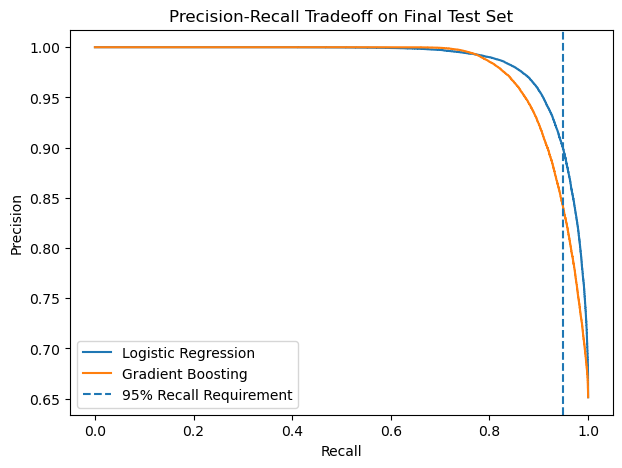

In [60]:
log_p, log_r, _ = precision_recall_curve(y_test,logistic_test_scores)
boost_p, boost_r, _ = precision_recall_curve(y_test,boost_test_scores)
plt.figure(figsize=(7, 5))
plt.plot(log_r,log_p,label="Logistic Regression")
plt.plot(boost_r,boost_p,label="Gradient Boosting")
plt.axvline(0.95,linestyle="--",label="95% Recall Requirement")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Tradeoff on Final Test Set")

plt.legend()
plt.show()
## catching more hazards usually means more unnessary interventions 

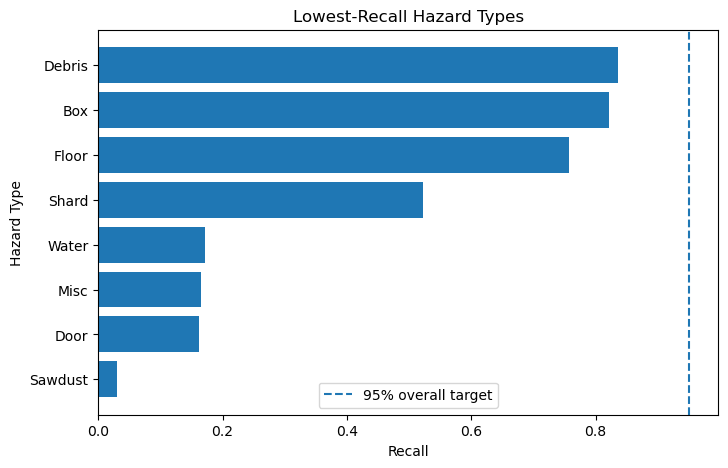

In [61]:
plot_df = (hazard_slice_df.head(8).sort_values("Recall"))
plt.figure(figsize=(8, 5))
plt.barh(plot_df["Hazard Type"],plot_df["Recall"])
plt.axvline(0.95,linestyle="--",label="95% overall target")
plt.xlabel("Recall")
plt.ylabel("Hazard Type")
plt.title("Lowest-Recall Hazard Types")
plt.legend()
plt.show()

In [62]:

# FINAL ANALYSIS SUMMARY

print("=== LOCKED HEADLINE METRIC ===")
display(headline_results)

print("\n=== FROZEN-THRESHOLD TEST PERFORMANCE ===")
display(frozen_threshold_results)

print("\n=== HAZARD FAILURE SLICES ===")
display(hazard_slice_df.head(10))

print("\n=== ENVIRONMENT SLICES ===")
display(environment_df)

print("\n=== UNSUPERVISED POLICY ===")
display(cluster_policy_results)

=== LOCKED HEADLINE METRIC ===


,Method,Precision at >=95% Recall,Recall at Operating Point
0,Always Hazard,0.651356,1.000000
1,CLIP Distance,0.732467,0.950009
2,Logistic Regression,0.897703,0.950009
3,Gradient Boosting,0.839049,0.950021



=== FROZEN-THRESHOLD TEST PERFORMANCE ===


,Method,Frozen Threshold,Test Precision,Test Recall
0,CLIP Distance,4.128906,0.840841,0.703166
1,Logistic Regression,0.794009,0.934370,0.924317
2,Gradient Boosting,0.459587,0.876537,0.931600



=== HAZARD FAILURE SLICES ===


,Hazard Label,Hazard Type,Recall,CI Low,CI High,Sample Size,Training Count
13,14,Sawdust,0.029412,0.011496,0.073183,136,253
5,6,Door,0.162210,0.134019,0.194996,561,707
8,9,Misc,0.165254,0.123306,0.217926,236,597
17,18,Water,0.172043,0.108765,0.261341,93,211
14,15,Shard,0.522936,0.429993,0.614316,109,39
6,7,Floor,0.757491,0.744462,0.770061,4305,4751
0,1,Box,0.821744,0.810863,0.832129,4976,5868
3,4,Debris,0.835658,0.824655,0.846100,4588,4474
11,12,Clutter,0.847584,0.814755,0.875484,538,659
1,2,Cable,0.866949,0.857447,0.875909,5201,5460



=== ENVIRONMENT SLICES ===


,Environment,Precision,Recall,Recall CI Low,Recall CI High,Sample Size,Hazard Sample Size
1,1,0.977648,0.892947,0.889487,0.896311,48298,31545
0,0,0.996292,0.927541,0.924514,0.930456,44682,29258
2,2,0.828137,0.961974,0.959467,0.964331,36866,23773



=== UNSUPERVISED POLICY ===


,Policy,Precision,Recall
0,Supervised model only,0.93437,0.924317
1,Model + risky cluster override,0.93437,0.924317
